In [43]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '2_train_clean2.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_val_fe.parquet')
test = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_test_fe.parquet')

train_full = pd.concat(
    [train, val]
)

print(train.shape, val.shape, train_full.shape, test.shape)

(616299, 35) (133325, 35) (749624, 35) (186263, 33)


In [ ]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

# 시계열 컬럼군
time_cols = [
    'wl_t',          # 수위데이터 대표
    'sfc_rain_1h',   # 육상 누적강수데이터 대표
    'imerg_rain_1h', # 위성 누적강수데이터 대표
    'radar_reflectivity_mean', # 레이더반사도 대표
    'radar_reflectivity_p95', # 레이더반사도 대표
]

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)}, 
    환경변수: {len(env_cols)}, 
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)}, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9, 
    환경변수: 7, 
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [23]:
# ============================================================
# 2. env_cols 분석 필요여부 확인하기
# ============================================================
# train, val셋과 train셋의 station_id가 동일하다면 불필

print(
    'train셋 \'station_id\' 개수: ',
    len(set(train['station_id']))
)

print(
    'train, val셋 \'station_id\' 교집합 개수: ',
    len(
        set(train['station_id']) & set(val['station_id'])
    )
)

print(
    'train, val, test셋 \'station_id\' 교집합 개수: ',
    len(
        set(train['station_id']) & set(val['station_id']) & set(test['station_id'])
    )
)

print(
    'test셋에만 있는 \'station_id\' 개수: ',
    len(set(test['station_id']) - set(train['station_id']) - set(val['station_id']))
)

# test셋도 1관측소당 유역환경변수가 중복없이 1데이터 인지 확인
test_env_gb = test.groupby('station_id')[env_cols].nunique().max()
print(test_env_gb)
# env_cols는 분석 제외

train셋 'station_id' 개수:  465
train, val셋 'station_id' 교집합 개수:  465
train, val, test셋 'station_id' 교집합 개수:  465
test셋에만 있는 'station_id' 개수:  0
cat_area          1
wsarea            1
mean_elevation    1
mean_slope        1
urban_ratio       1
forest_ratio      1
stream_order      1
dtype: int64


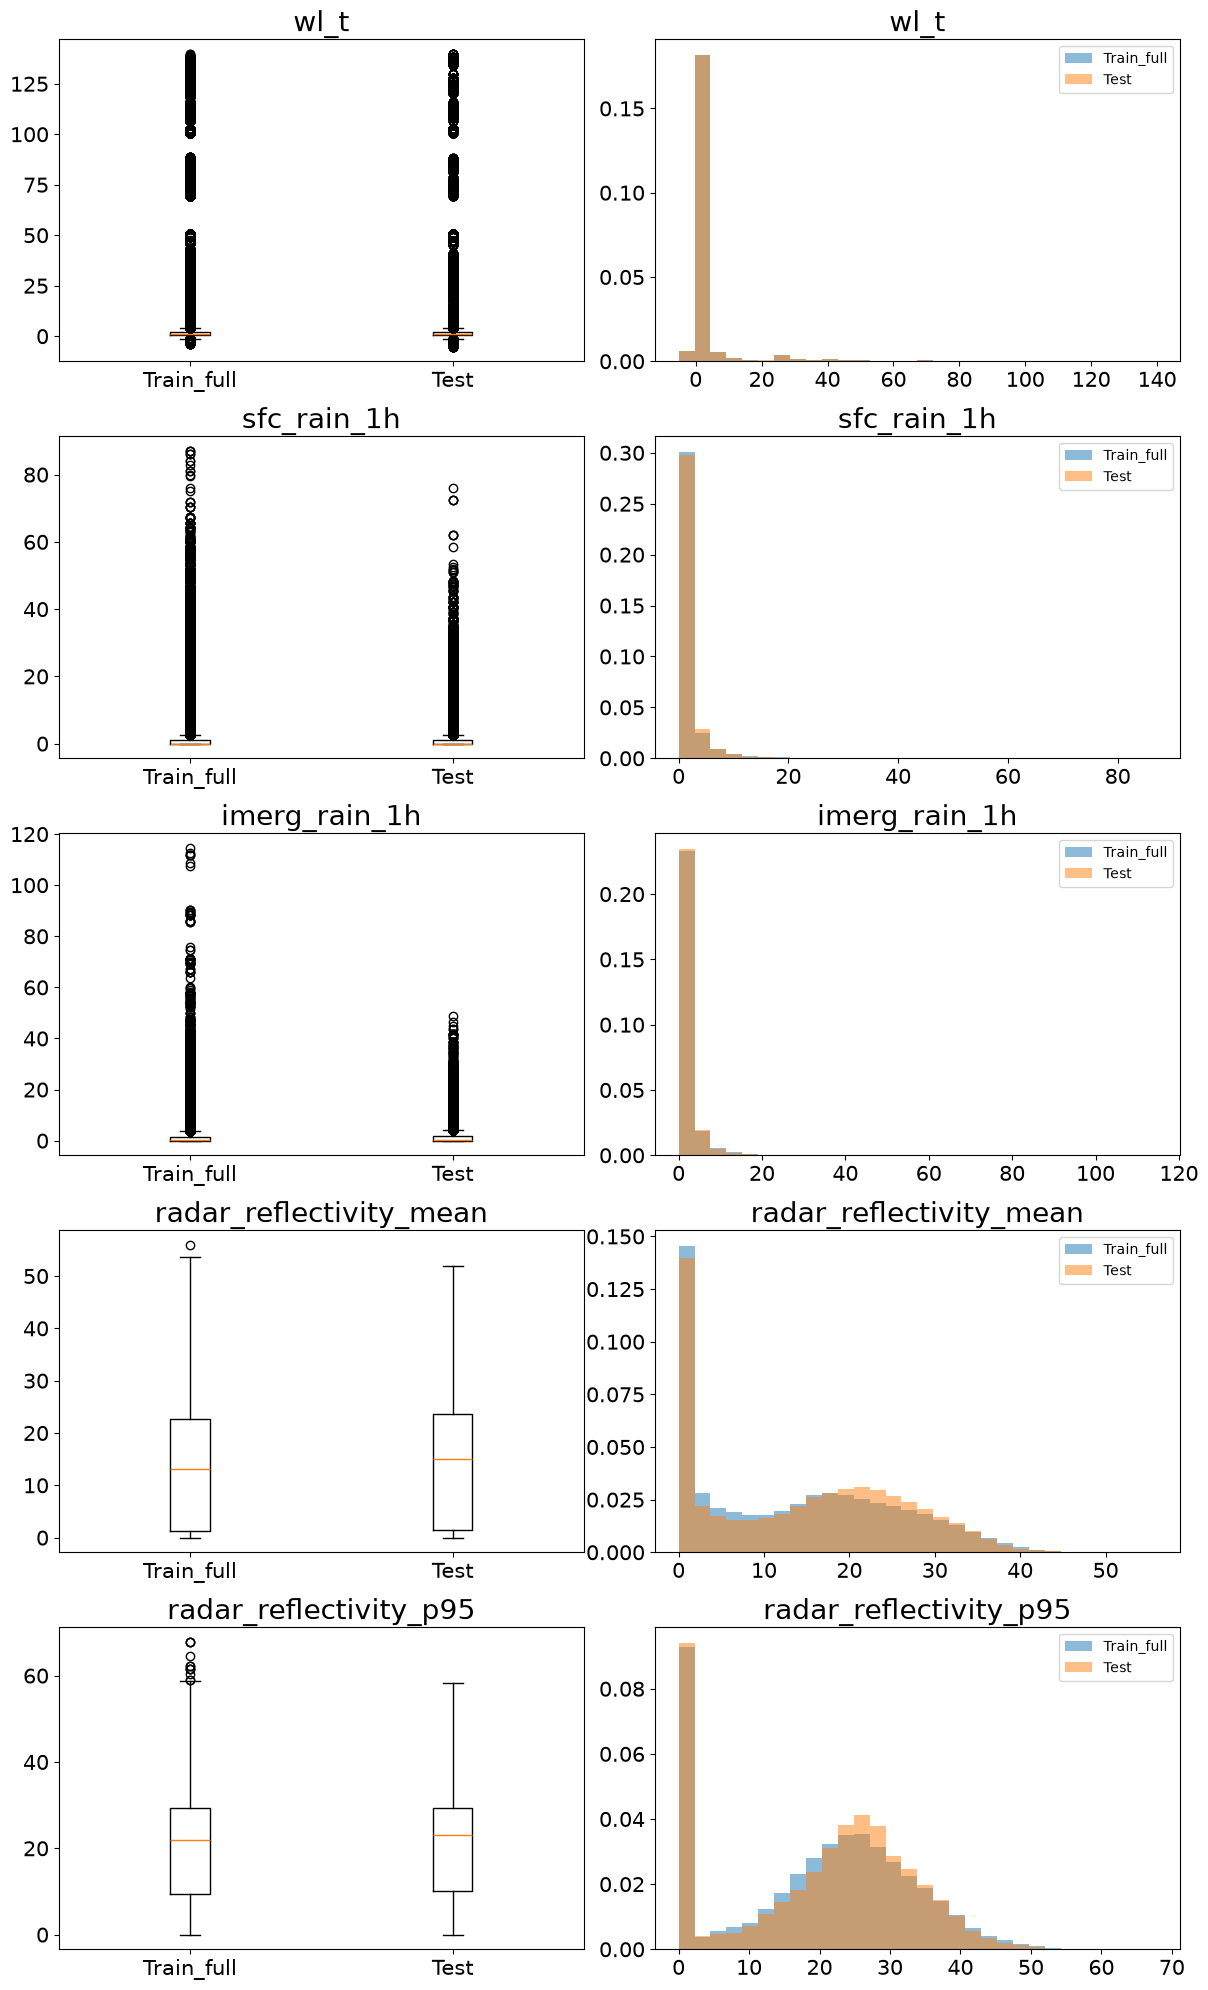

In [ ]:
# ======================================================================
# 3-1. (시계열) train, val 데이터 박스플롯, 히스토그램 비교하기: 분포 비교용
# ======================================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(time_cols),
    2,
    figsize = (12, 4 * len(time_cols)))

if len(time_cols) == 1:
    axes = [axes]

for i, col in enumerate(time_cols):
    
    tr_f = train_full[col].dropna()
    te = test[col].dropna()

    axes[i][0].boxplot([tr_f, te], tick_labels=['Train_full', 'Test'])
    axes[i][0].set_title(col, fontsize=20)
    axes[i][0].tick_params(labelsize=15)

    axes[i][1].hist(
        tr_f,
        range=(min(tr_f.min(), te.min()), max(tr_f.max(), te.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Train_full'
    )
    axes[i][1].hist(
        te,
        range=(min(tr_f.min(), te.min()), max(tr_f.max(), te.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Test'
    )
    axes[i][1].set_title(col, fontsize=20)
    axes[i][1].tick_params(labelsize=15)
    axes[i][1].legend

plt.tight_layout()
plt.show()

In [53]:
# ======================================================================
# 3-2. (시계열) 기초통계량 비교: 시계열데이터 전부 다 비교
# ======================================================================

q = [0, 0.01, 0.05, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]

for col in [col for col in num_cols_fe if col not in env_cols]:
    print(col)
    print(pd.DataFrame(
        {
            'Train' : train[col].quantile(q).round(1),
            'Validation' : val[col].quantile(q).round(1),
            'Val/Train' : (val[col].quantile(q)/train[col].quantile(q)).round(1),
            'Train_full' : train_full[col].quantile(q).round(1),
            'Test' : test[col].quantile(q).round(1),
            'Test/Train_f': (test[col].quantile(q)/train_full[col].quantile(q)).round(1),
            'Test/Val' : (test[col].quantile(q)/val[col].quantile(q)).round(1)
        }
    )
    .to_csv(sep='\t'))
    print()


wl_t
	Train	Validation	Val/Train	Train_full	Test	Test/Train_f	Test/Val
0.0	-3.8	-3.8	1.0	-3.8	-5.2	1.3	1.3
0.01	-1.0	-1.1	1.1	-1.0	-1.0	1.0	1.0
0.05	-0.1	-0.1	1.1	-0.1	-0.1	1.2	1.1
0.5	1.1	1.1	1.0	1.1	1.2	1.0	1.0
0.75	2.0	1.9	1.0	2.0	2.0	1.0	1.1
0.9	4.0	3.7	0.9	4.0	4.0	1.0	1.1
0.95	25.0	25.0	1.0	25.0	25.0	1.0	1.0
0.99	78.8	79.3	1.0	78.8	81.4	1.0	1.0
1.0	139.6	136.8	1.0	139.6	139.7	1.0	1.0


wl_t_minus_1h
	Train	Validation	Val/Train	Train_full	Test	Test/Train_f	Test/Val
0.0	-3.9	-3.7	0.9	-3.9	-5.2	1.3	1.4
0.01	-1.0	-1.1	1.1	-1.0	-1.0	1.0	1.0
0.05	-0.1	-0.1	1.0	-0.1	-0.1	1.1	1.1
0.5	1.1	1.1	1.0	1.1	1.1	1.0	1.0
0.75	2.0	1.9	1.0	2.0	2.0	1.0	1.1
0.9	4.0	3.7	0.9	3.9	4.0	1.0	1.1
0.95	25.0	25.0	1.0	25.0	25.0	1.0	1.0
0.99	78.8	79.3	1.0	78.8	81.3	1.0	1.0
1.0	139.7	136.8	1.0	139.7	139.7	1.0	1.0


wl_t_minus_3h
	Train	Validation	Val/Train	Train_full	Test	Test/Train_f	Test/Val
0.0	-3.9	-3.7	0.9	-3.9	-5.2	1.3	1.4
0.01	-1.0	-1.1	1.1	-1.0	-1.0	1.0	1.0
0.05	-0.1	-0.1	1.1	-0.1	-0.1	1.2	1.1
0.5	1.1	1.1	1

In [50]:
# 수위변수군의 0분위수 중에 test셋에서만 -5.2 기록
# 0.05분위수는 -0.1로 tr, va, te 모두 동일
# -5.2 이상치가 의심됨

cond_test_min_wl = test['wl_t'] < -5
print(f"6h이내 수위변동이 -2보다 작은 데이터 개수: {cond_test_min_wl.sum()}")
test.loc[cond_test_min_wl, ['timestamp', 'station_id'] + time_cols]

# test.loc[
#     (test['station_id'] == 'ST0436') &
#     (test['timestamp'].between(
#         '2102-12-26 00:00:00',
#         '2102-12-28 12:00:00'
#     )),
#     ['timestamp', 'station_id'] + time_cols
# ].sort_values('timestamp')

print(
    test.loc[
        test['station_id'] == 'ST0436',
        ['timestamp', 'station_id'] + time_cols
    ]
    .sort_values(['wl_t', 'timestamp'])
    .to_csv(sep='\t')
)

6h이내 수위변동이 -2보다 작은 데이터 개수: 13
row_id	timestamp	station_id	wl_t	sfc_rain_1h	imerg_rain_1h	radar_reflectivity_mean	radar_reflectivity_p95
TE_000166886	2102-12-27 00:00:00	ST0436	-5.18	0.0	0.906	3.938	22.0
TE_000118763	2102-12-27 01:00:00	ST0436	-5.17	0.0	0.932	10.831	18.2
TE_000050700	2102-12-27 02:00:00	ST0436	-5.17	0.0	1.749	15.008	18.965
TE_000171285	2102-12-27 03:00:00	ST0436	-5.16	0.0	2.921	22.138	25.09
TE_000044147	2102-12-27 04:00:00	ST0436	-5.16	0.5	4.124	27.269	29.45
TE_000107495	2102-12-27 05:00:00	ST0436	-5.15	2.0	3.049	25.945	27.894
TE_000151241	2102-12-27 06:00:00	ST0436	-5.15	1.5	2.213	23.589	26.8
TE_000182268	2102-12-27 07:00:00	ST0436	-5.14	1.0	2.52	23.598	26.7
TE_000162483	2102-12-27 08:00:00	ST0436	-5.13	1.0	3.418	27.653	29.89
TE_000115939	2102-12-27 09:00:00	ST0436	-5.13	1.5	3.885	25.364	28.098
TE_000184196	2102-12-27 10:00:00	ST0436	-5.12	2.0	3.451	28.232	31.74
TE_000176595	2102-12-27 12:00:00	ST0436	-5.12	2.0	0.43	25.924	27.57
TE_000100776	2102-12-27 11:00:00	ST0436	

In [ ]:
# 수위차분변수에서는 12h, 24h의 0분위수와 1분위수, 즉 극단값에서 차이가 확인되어 추가분석 실시

# 12h 수위차분변수는 train만 0, 1분위수가 유독 낫고 높음, 확인필요
cond = (train['wl_diff_12h'] < -4) | (train['wl_diff_12h'] > 7)

print(f'해당 행 수: {cond.sum()}')

# train.loc[cond, [
#     'timestamp', 'station_id',
#     'wl_diff_12h' 
# ] + wl_cols
# ].sort_values(['wl_diff_12h', 'timestamp'])

train.loc[
    (train['station_id'] == 'ST0089') &
    (train['timestamp'].between(
        '2101-12-31 00:00:00',
        '2102-01-02 00:00:00'
    )),
    ['timestamp', 'station_id', 'wl_diff_12h'] + wl_cols
].sort_values(['wl_diff_12h', 'timestamp'])

# train ST0089 3개 이상치 확정

해당 행 수: 44


,timestamp,station_id,wl_diff_12h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000547855,2102-01-01 07:00:00,ST0089,-6.35,0.03,0.01,0.01,6.38,6.38,6.38
TR_000457689,2102-01-01 10:00:00,ST0089,-6.27,0.11,0.10,0.03,0.01,6.38,6.38
TR_000318564,2102-01-01 21:00:00,ST0089,0.37,0.47,0.42,0.18,0.16,0.10,6.38


In [ ]:
# 24h 수위차분변수는 0분위수가 모두 0.05분위수에 비해 크게 낮음

for name, df in [('Train', train), ('Validation', val), ('Test', test)]:

    cond = df['wl_diff_24h'] < -5

    print(f'\n{name}: {cond.sum()}행')

    display(
        df.loc[
            cond,
            ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
        ].sort_values(['wl_diff_24h', 'timestamp'])
    )

# train ST0158 3개 이상치 확정
# val ST0448 8개, ST0007 1개 이상치 확정
# test ST015 1개 이상치 확정


Train: 33행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000076779,2103-06-10 03:00:00,ST0412,-8.85,2.49,2.73,3.29,4.19,6.11,11.34
TR_000260409,2103-06-10 04:00:00,ST0412,-8.75,2.29,2.49,3.01,3.89,5.78,11.04
TR_000194526,2103-06-10 02:00:00,ST0412,-8.64,2.73,3.01,3.59,4.49,6.47,11.37
TR_000001659,2103-06-10 05:00:00,ST0412,-8.49,2.13,2.29,2.73,3.59,5.47,10.62
TR_000628761,2103-06-10 06:00:00,ST0412,-8.18,2.00,2.13,2.49,3.29,5.13,10.18
TR_000514035,2103-06-10 01:00:00,ST0412,-7.91,3.01,3.29,3.89,4.80,6.89,10.92
TR_000222952,2103-06-10 07:00:00,ST0412,-7.91,1.90,2.00,2.29,3.01,4.80,9.81
TR_000255390,2103-06-10 08:00:00,ST0412,-7.58,1.81,1.90,2.13,2.73,4.49,9.39
TR_000193482,2102-05-11 00:00:00,ST0158,-7.39,0.00,0.00,0.00,0.00,0.00,7.39



Validation: 38행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000468355,2103-12-02 00:00:00,ST0448,-9.59,0.00,0.00,0.00,0.00,0.00,9.59
TR_000450715,2103-12-02 01:00:00,ST0448,-9.59,0.00,0.00,0.00,0.00,0.00,9.59
TR_000267036,2103-12-02 02:00:00,ST0448,-9.59,0.00,0.00,0.00,0.00,0.00,9.59
TR_000185855,2103-12-02 04:00:00,ST0448,-9.59,0.00,0.00,0.00,0.00,0.00,9.59
TR_000385460,2103-12-02 05:00:00,ST0448,-9.59,0.00,0.00,0.00,0.00,0.00,9.59
TR_000665570,2103-12-02 06:00:00,ST0448,-9.59,0.00,0.00,0.00,0.00,0.00,9.59
TR_000480061,2103-12-02 07:00:00,ST0448,-9.59,0.00,0.00,0.00,0.00,0.00,9.59
TR_000476408,2103-12-02 03:00:00,ST0448,-9.57,0.00,0.00,0.00,0.00,0.00,9.57
TR_000715299,2103-12-02 00:00:00,ST0007,-8.75,0.00,0.00,0.00,0.00,0.00,8.75



Test: 4행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TE_000112883,2102-12-27 07:00:00,ST0158,-6.31,0.22,0.22,0.22,0.22,0.23,6.53
TE_000161627,2102-06-30 03:00:00,ST0326,-5.81,-3.15,-2.55,-0.84,1.96,-2.32,2.66
TE_000046077,2102-06-30 04:00:00,ST0326,-5.76,-3.10,-3.15,-1.69,1.35,-2.29,2.66
TE_000148339,2102-06-30 02:00:00,ST0326,-5.21,-2.55,-1.69,0.32,1.77,-1.71,2.66


In [ ]:
# 24h 수위차분변수 train셋 ST0158 갑자기 7.39m 수위 기록 확인

cond = (
    (train['station_id'] == 'ST0158') &
    (train['timestamp'].between(
        '2102-05-08 00:00:00',
        '2102-05-14 23:00:00'
    ))
)

print(f'해당 행 수: {cond.sum()}')

train.loc[
    cond,
    ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
].sort_values('timestamp')

해당 행 수: 3


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000193482,2102-05-11 00:00:00,ST0158,-7.39,0.0,0.0,0.0,0.0,0.0,7.39
TR_000057205,2102-05-11 01:00:00,ST0158,-7.39,0.0,0.0,0.0,0.0,0.0,7.39
TR_000154692,2102-05-11 02:00:00,ST0158,-7.39,0.0,0.0,0.0,0.0,0.0,7.39


In [71]:
# 24h 수위차분변수 Val셋 ST0448 갑자기 9.59m 수위 기록 확인
cond = (
    (val['station_id'] == 'ST0448') &
    (val['timestamp'].between(
        '2103-11-29 00:00:00',
        '2103-12-05 23:00:00'
    ))
)

print(f'해당 행 수: {cond.sum()}')

val.loc[
    cond,
    ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
].sort_values('timestamp')
print()

# 24h 수위차분변수 Val셋 ST0007 갑자기 8.75m 수위 기록 확인
cond = (
    (val['station_id'] == 'ST0007') &
    (val['timestamp'].between(
        '2103-11-29 00:00:00',
        '2103-12-05 23:00:00'
    ))
)

print(f'해당 행 수: {cond.sum()}')

val.loc[
    cond,
    ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
].sort_values('timestamp')

해당 행 수: 8

해당 행 수: 8


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000715299,2103-12-02 00:00:00,ST0007,-8.75,0.0,0.0,0.0,0.0,0.0,8.75
TR_000581814,2103-12-02 01:00:00,ST0007,-0.01,0.0,0.0,0.0,0.0,0.0,0.01
TR_000127840,2103-12-02 02:00:00,ST0007,0.00,0.0,0.0,0.0,0.0,0.0,0.00
TR_000586773,2103-12-02 03:00:00,ST0007,0.00,0.0,0.0,0.0,0.0,0.0,0.00
TR_000387000,2103-12-02 04:00:00,ST0007,0.00,0.0,0.0,0.0,0.0,0.0,0.00
TR_000415774,2103-12-02 05:00:00,ST0007,0.00,0.0,0.0,0.0,0.0,0.0,0.00
TR_000696281,2103-12-02 06:00:00,ST0007,0.00,0.0,0.0,0.0,0.0,0.0,0.00
TR_000392699,2103-12-02 07:00:00,ST0007,0.00,0.0,0.0,0.0,0.0,0.0,0.00


In [73]:
# 24h 수위차분변수 Test셋 ST0158 갑자기 6.53m 수위 기록 확인
cond = (
    (test['station_id'] == 'ST0158') &
    (test['timestamp'].between(
        '2102-12-24 00:00:00',
        '2102-12-30 23:00:00'
    ))
)

print(f'해당 행 수: {cond.sum()}')

test.loc[
    cond,
    ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
].sort_values('timestamp')

해당 행 수: 4


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TE_000112883,2102-12-27 07:00:00,ST0158,-6.31,0.22,0.22,0.22,0.22,0.23,6.53
TE_000054685,2102-12-27 08:00:00,ST0158,0.01,0.22,0.22,0.22,0.22,0.23,0.21
TE_000063023,2102-12-27 09:00:00,ST0158,0.00,0.20,0.22,0.22,0.22,0.23,0.20
TE_000131077,2102-12-27 10:00:00,ST0158,-0.01,0.19,0.20,0.22,0.22,0.23,0.20


In [74]:
# 24h 수위차분변수는 1분위수가 train셋이 11.6으로 월등함
# 일단 세가지 차이가 명확하므로 다 탐색

for name, df in [('Train', train), ('Validation', val), ('Test', test)]:

    cond = df['wl_diff_24h'] > 5

    print(f'\n{name}: {cond.sum()}행')

    display(
        df.loc[
            cond,
            ['timestamp', 'station_id', 'wl_diff_24h'] + wl_cols
        ].sort_values(['wl_diff_24h', 'timestamp'])
    )


Train: 271행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000076110,2101-03-08 17:00:00,ST0284,5.01,6.05,4.61,2.97,2.12,1.69,1.04
TR_000623182,2103-06-09 10:00:00,ST0313,5.01,6.71,6.93,7.17,6.89,3.45,1.70
TR_000699723,2101-03-08 19:00:00,ST0409,5.01,9.71,9.36,8.55,6.47,4.75,4.70
TR_000429714,2101-03-08 14:00:00,ST0353,5.02,7.14,6.82,6.22,5.31,4.06,2.12
TR_000130863,2101-03-08 21:00:00,ST0179,5.02,14.33,13.99,13.33,11.89,9.30,9.31
TR_000137626,2101-03-08 14:00:00,ST0413,5.03,4.16,3.48,1.49,-0.06,-0.84,-0.87
TR_000435479,2103-06-06 04:00:00,ST0116,5.04,6.75,6.93,6.21,3.20,1.56,1.71
TR_000604908,2101-03-08 17:00:00,ST0071,5.05,5.96,5.39,4.00,2.02,0.90,0.91
TR_000537436,2101-03-08 20:00:00,ST0353,5.05,8.51,8.60,8.20,7.14,5.31,3.46



Validation: 6행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
TR_000234703,2104-02-10 10:00:00,ST0116,5.04,6.78,6.59,2.58,1.82,1.62,1.74
TR_000393620,2104-02-10 16:00:00,ST0221,5.10,8.26,8.68,9.24,5.12,3.06,3.16
TR_000669988,2104-02-10 15:00:00,ST0221,5.51,8.68,9.02,9.12,3.49,3.05,3.17
TR_000501279,2104-02-10 14:00:00,ST0221,5.85,9.02,9.24,8.03,3.40,3.05,3.17
TR_000318860,2104-02-10 12:00:00,ST0221,5.94,9.12,8.03,3.49,3.20,3.08,3.18
TR_000677220,2104-02-10 13:00:00,ST0221,6.07,9.24,9.12,5.12,3.30,3.06,3.17



Test: 0행


,timestamp,station_id,wl_diff_24h,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,,,,
